In [ ]:
# ==============================================================================
# CORE MATHEMATICAL FRAMEWORK: REACTION-DIFFUSION EQUATION
# ==============================================================================
#
# General Equation:
# du/dt = D * ∇²u + f(u)
#
# Variables & Terms:
#   u      : Concentration of the biological substance, u(x, t)
#   du/dt  : The rate of change in concentration over time.
#   D      : Diffusion coefficient (controls the speed of spatial spreading).
#   ∇²u    : The Laplacian of u (describes how the substance diffuses through
#            space). In 1D, this represents the second spatial derivative (d²u/dx²).
#   f(u)   : The reaction term. Describes local biological interactions like
#            production, decay, binding, or cell division.


NO = 0.103 uM, promoter threshold = 0.0013 uM
promoter is ON  (Hill = 0.9998)
enzyme penetration depth lambda = sqrt(D_E/gamma_E) = 301 um

t =  0 h   eDNA  0.2400 uM    -0.0% cleared   top  0.2400   bottom  0.2400
t =  1 h   eDNA  0.1900 uM    20.8% cleared   top  0.0685   bottom  0.2377
t =  2 h   eDNA  0.1358 uM    43.4% cleared   top  0.0121   bottom  0.2195
t =  4 h   eDNA  0.0759 uM    68.4% cleared   top  0.0004   bottom  0.1675
t =  8 h   eDNA  0.0301 uM    87.5% cleared   top  0.0000   bottom  0.0920
t = 12 h   eDNA  0.0135 uM    94.4% cleared   top  0.0000   bottom  0.0501


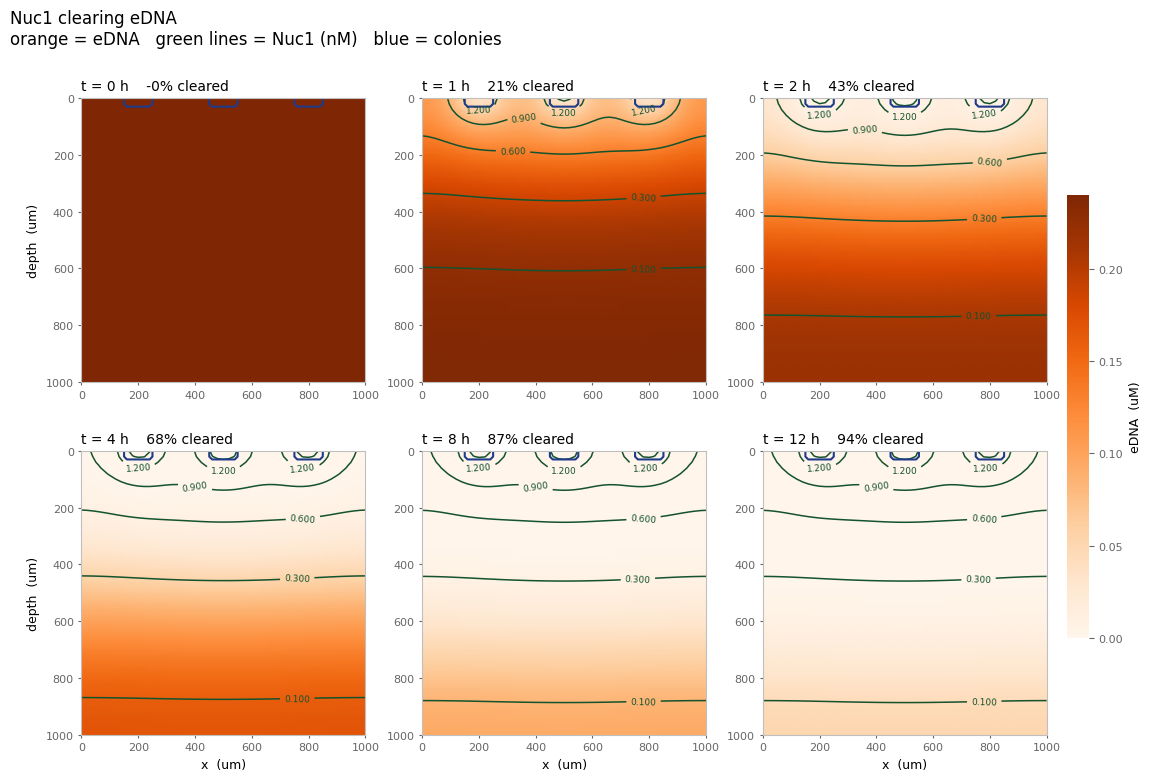

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- the NO signal ----------
NO = 0.103        # uM. steady state from our own DETA-NONOate donor model
K_half = 0.0013   # uM. pPnorVbeta. NOTE this is the reported LOD (1.3 nM), not a
                  # measured half-maximal constant. real K_half is higher, so this
                  # overstates how strongly the promoter is induced.
                  # swap to 20 for the native PnorV promoter (10-50 uM, Chen 2021)
h = 2             # Hill coefficient, 3 NorR binding sites

# ---------- Nuc1 ----------
D_E = 35.0        # um^2/s in biofilm. midpoint of 20-50. Erickson 2009, Cao 2022
kcat = 2.0        # 1/s at pH 7.0-7.4. midpoint of 1-3. Serpersu 1987, pH corrected
Km = 4.3          # uM DNA at pH 7.4. BRENDA EC 3.1.31.1 / Cuatrecasas 1967
B0 = 0.24         # uM eDNA. 24 ug/mL, Dengler 2015, using 1 uM = 100 ug/mL

# proteases in the wound destroy our enzyme. this is what gives it a finite
# penetration depth instead of filling the whole biofilm
gamma_E = np.log(2)/(30*60)   # <<< ASSUMED. 30 min half life. no published value

# secretion ceiling turned into uM/s
k_sec = 20        # molecules per cell per second. Horga 2018
n_cells = 4e8     # cells per cm3 at OD600 0.5
NA = 6.022e23
R_max = k_sec*n_cells/NA*1e3*1e6

# ---------- the grid ----------
L = 1000          # um. 1 mm square. chosen so the depth gradient is visible;
                  # wound biofilms do reach this thickness
dz = 20           # um
n = int(L/dz)+1
x = np.linspace(0, L, n)
X, Z = np.meshgrid(x, x, indexing='xy')     # X sideways, Z depth

# three colonies on top, each 120 um wide and 40 um deep
# <<< ASSUMED layout. changes the shape of the lobes, not the clearance rate
cells = np.zeros((n, n))
for spot in [200, 500, 800]:
    cells[(Z < 40) & (np.abs(X - spot) < 60)] = 1

# NO comes from outside and is uniform, so this is just one number
hill = NO**h/(K_half**h + NO**h)
print("NO = %.3f uM, promoter threshold = %.4f uM" % (NO, K_half))
print("promoter is %s  (Hill = %.4f)" % ("ON" if hill > 0.5 else "OFF", hill))
print("enzyme penetration depth lambda = sqrt(D_E/gamma_E) = %.0f um" % np.sqrt(D_E/gamma_E))
print()

# ---------- time ----------
delta_t = 2                   # s. stability needs dt <= dz^2/(4*D_E) = 2.86 s
total_time = 12*3600
num_step = int(total_time/delta_t)

save_times = [0, 1, 2, 4, 8, 12]
save_steps = [int(t*3600/delta_t) for t in save_times]
saved_E, saved_B = [], []

# 2D laplacian. 'edge' padding copies the border outward = nothing leaks out
def laplacian(u):
    q = np.pad(u, 1, mode='edge')
    return (q[2:,1:-1] + q[:-2,1:-1] + q[1:-1,2:] + q[1:-1,:-2] - 4*u)/dz**2

enzyme  = np.zeros((n, n))          # no enzyme at the start
biofilm = np.zeros((n, n)) + B0     # eDNA everywhere at the start

for i in range(num_step + 1):

    if i in save_steps:
        saved_E.append(enzyme.copy())
        saved_B.append(biofilm.copy())

    # enzyme spreads, colonies make more, proteases destroy it
    denzyme_dt = D_E*laplacian(enzyme) + R_max*hill*cells - gamma_E*enzyme

    # eDNA gets chewed up. enzyme is a catalyst so it is not used up
    dbiofilm_dt = -(kcat*enzyme*biofilm)/(Km + biofilm)

    enzyme  = enzyme  + delta_t*denzyme_dt
    biofilm = biofilm + delta_t*dbiofilm_dt
    biofilm[biofilm < 0] = 0        # cannot go negative

for t, B in zip(save_times, saved_B):
    print("t = %2d h   eDNA %7.4f uM   %5.1f%% cleared   top %7.4f   bottom %7.4f"
          % (t, B.mean(), 100*(1-B.mean()/B0), B[:3].mean(), B[-3:].mean()))

# ---------- plot ----------
fig, axes = plt.subplots(2, 3, figsize=(13, 8.4))

# enzyme contour levels in nM. these must sit inside the enzyme's actual range,
# so recheck them with print(E.min()*1e3, E.max()*1e3) if you change a constant
lv = [0.1, 0.3, 0.6, 0.9, 1.2, 1.5]

for ax, t, E, B in zip(axes.ravel(), save_times, saved_E, saved_B):
    im = ax.pcolormesh(x, x, B, cmap='Oranges', vmin=0, vmax=B0, shading='gouraud')
    e = E*1e3
    sel = [v for v in lv if e.min() < v < e.max()]
    if sel:
        cs = ax.contour(x, x, e, levels=sel, colors='#14532d', linewidths=1.1)
        ax.clabel(cs, inline=True, fontsize=6.5, fmt='%.3f')
    ax.contour(x, x, cells, levels=[0.5], colors='#1e3a8a', linewidths=1.5)
    ax.invert_yaxis()
    ax.set_aspect('equal')
    ax.set_title("t = %d h    %.0f%% cleared" % (t, 100*(1-B.mean()/B0)), fontsize=10, loc='left')
    ax.tick_params(labelsize=8, colors='0.4', length=2)
    for s in ax.spines.values():
        s.set_color('0.75')

for ax in axes[1]:
    ax.set_xlabel("x  (um)", fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("depth  (um)", fontsize=9)

cb = fig.colorbar(im, ax=axes, fraction=0.022, pad=0.02)
cb.set_label("eDNA  (uM)", fontsize=9)
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=8, colors='0.4')

fig.suptitle("Nuc1 clearing eDNA\n"
             "orange = eDNA   green lines = Nuc1 (nM)   blue = colonies",
             x=0.07, ha='left', fontsize=12)
plt.show()